# 02 · Trend Following, Done Properly

**Question:** Does a moving-average crossover actually beat buy-and-hold on Indian equities — and
how would we *know* if the result is skill rather than luck?

A typical "50/200 SMA on one stock" backtest has four silent flaws. This module fixes each:

| Common flaw | Fix here |
|---|---|
| Zero trading costs | 10 bps per side (brokerage + STT + slippage on NIFTYBEES/futures) |
| Cash earns 0% when out of the market | Cash earns the NSE overnight rate (NIFTY 1D Rate Index) |
| One hand-picked parameter set | Full 50 × parameter grid → heat-map, **Deflated Sharpe Ratio** |
| One asset, one period | Walk-forward parameter selection + robustness across **12 sector indices** |

We also add a modern alternative: **volatility targeting**, which exploits the volatility
clustering measured in module 01.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if (Path.cwd().parent / "src").exists() else "src")

import numpy as np
import pandas as pd

from nql import data, metrics
from nql.plotting import PALETTE, plt, save

COST = 0.0010  # per unit of turnover (one side)
px = data.nifty()
ret = px.pct_change().fillna(0)
rf = data.risk_free_daily(px.index)


def run(position: pd.Series, r: pd.Series = ret, rf_: pd.Series = rf) -> pd.Series:
    """position decided at close t is held during t+1 (no look-ahead). Idle cash earns rf."""
    pos = position.shift(1).fillna(0).clip(0, 1)
    turnover = pos.diff().abs().fillna(pos.abs())
    return pos * r + (1 - pos) * rf_.reindex(r.index).fillna(0) - turnover * COST


def sma_signal(p: pd.Series, fast: int, slow: int) -> pd.Series:
    return (p.rolling(fast).mean() > p.rolling(slow).mean()).astype(float)


START = px.index[300]  # common start after the longest look-back
bh = ret.loc[START:]
rf_s = rf.loc[START:]

## 1 · The classic 50/200 "golden cross" with realistic frictions

In [2]:
classic = run(sma_signal(px, 50, 200)).loc[START:]
classic_no_cost_no_rf = (sma_signal(px, 50, 200).shift(1).fillna(0) * ret).loc[START:]
rows = [metrics.summary(bh, rf_s, name="NIFTY 50 buy & hold"),
        metrics.summary(classic_no_cost_no_rf, rf_s, name="SMA 50/200 — naive (no costs, 0% cash)"),
        metrics.summary(classic, rf_s, bh, name="SMA 50/200 — realistic")]
metrics.table(rows)[["cagr", "vol", "sharpe", "max_dd", "calmar"]]

,cagr,vol,sharpe,max_dd,calmar
name,,,,,
NIFTY 50 buy & hold,10.9%,16.2%,0.38,-38.4%,0.28
"SMA 50/200 — naive (no costs, 0% cash)",4.2%,12.2%,-0.06,-42.4%,0.10
SMA 50/200 — realistic,5.7%,12.2%,0.06,-40.3%,0.14


## 2 · Volatility targeting

Scale exposure each day to `target_vol / forecast_vol`, capped at 100% (long-only, no leverage).
The vol forecast is an EWMA (RiskMetrics λ = 0.94) — a cheap, robust proxy for GARCH.

In [3]:
TARGET = 0.12
ewma_vol = np.sqrt((ret**2).ewm(alpha=1 - 0.94).mean() * 252)
vt_pos = (TARGET / ewma_vol).clip(upper=1.0)
vol_target = run(vt_pos).loc[START:]
trend_vt = run(sma_signal(px, 50, 200) * vt_pos).loc[START:]
rows += [metrics.summary(vol_target, rf_s, bh, name="Vol-target 12%"),
         metrics.summary(trend_vt, rf_s, bh, name="Trend × Vol-target")]
perf = metrics.table(rows)
perf[["cagr", "vol", "sharpe", "sortino", "max_dd", "calmar"]]

,cagr,vol,sharpe,sortino,max_dd,calmar
name,,,,,,
NIFTY 50 buy & hold,10.9%,16.2%,0.38,0.52,-38.4%,0.28
"SMA 50/200 — naive (no costs, 0% cash)",4.2%,12.2%,-0.06,-0.08,-42.4%,0.10
SMA 50/200 — realistic,5.7%,12.2%,0.06,0.07,-40.3%,0.14
Vol-target 12%,7.7%,11.7%,0.22,0.30,-20.5%,0.38
Trend × Vol-target,5.6%,9.9%,0.04,0.05,-26.8%,0.21


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


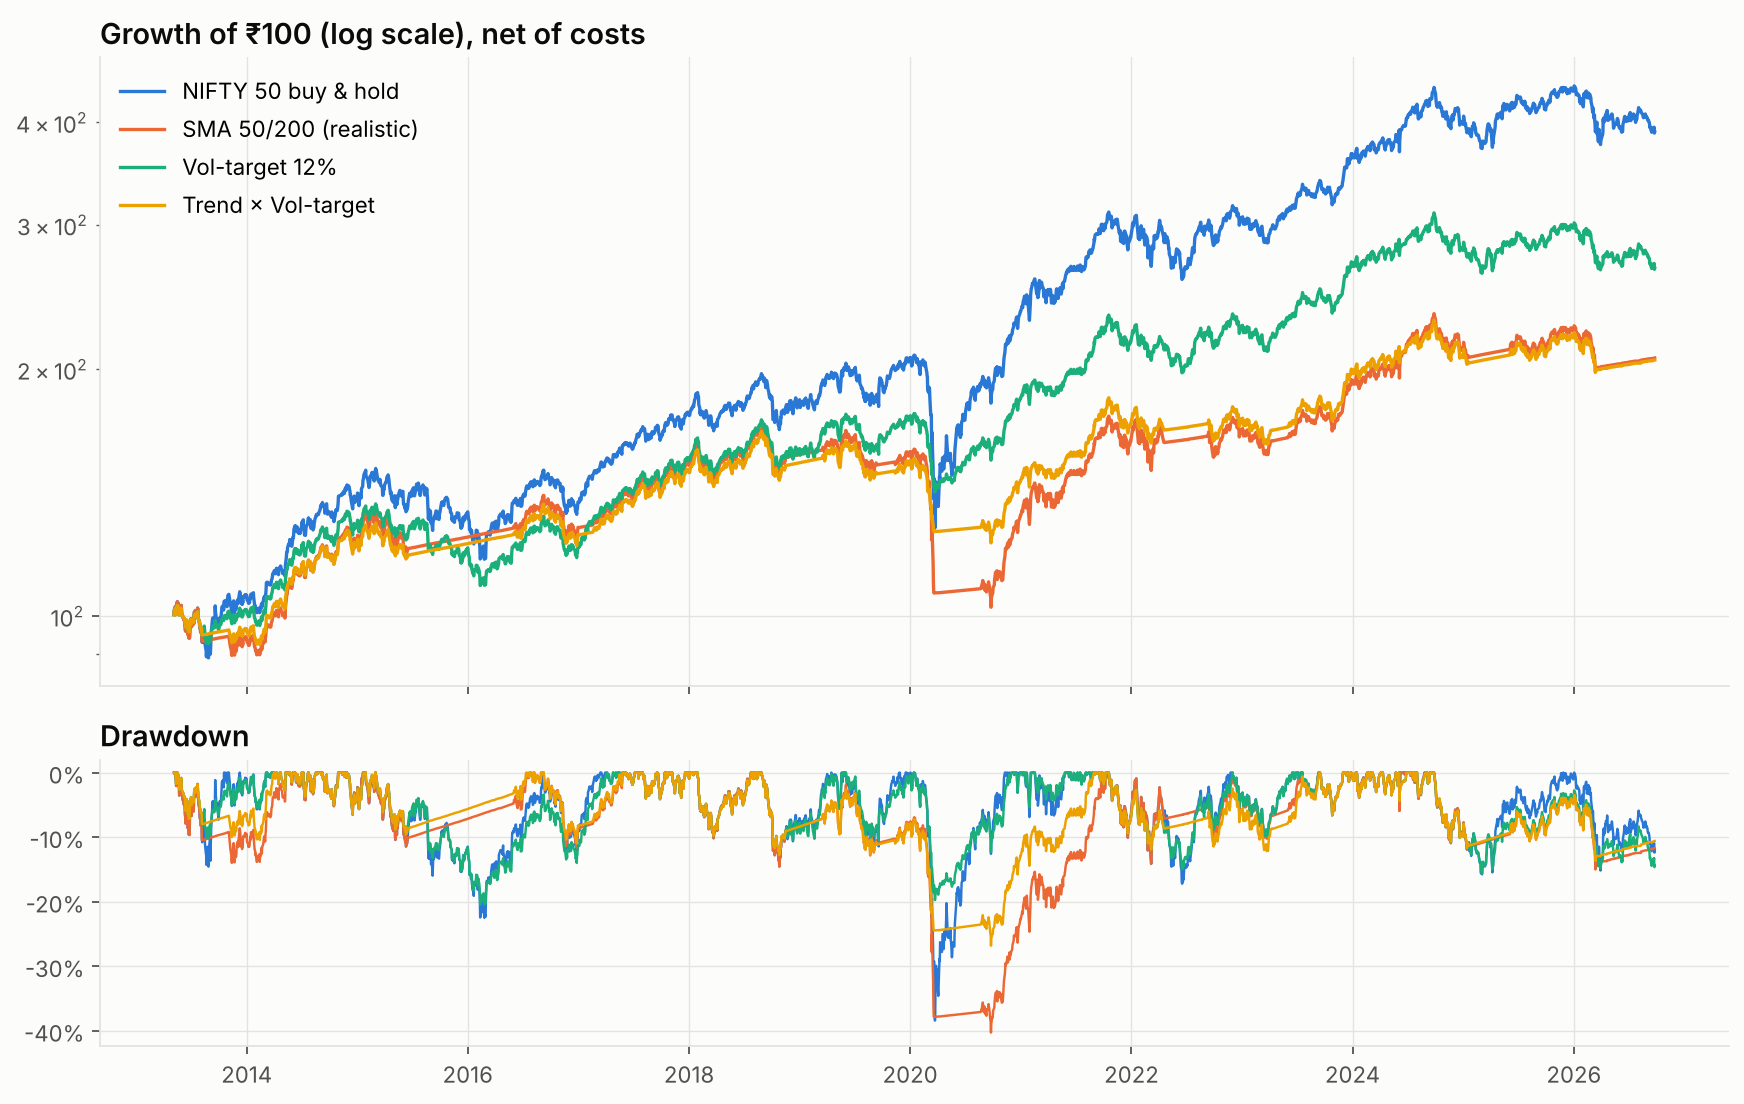

PosixPath('/home/claude/nse-quant-lab/reports/figures/02_equity_curves.png')

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
series = {"NIFTY 50 buy & hold": bh, "SMA 50/200 (realistic)": classic,
          "Vol-target 12%": vol_target, "Trend × Vol-target": trend_vt}
for i, (k, v) in enumerate(series.items()):
    w = (1 + v).cumprod() * 100
    axes[0].plot(w.index, w, color=PALETTE[i], lw=1.5, label=k)
    axes[1].plot(w.index, metrics.drawdown(v), color=PALETTE[i], lw=1.1)
axes[0].set_yscale("log"); axes[0].set_title("Growth of ₹100 (log scale), net of costs"); axes[0].legend()
axes[1].set_title("Drawdown"); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save(fig, "02_equity_curves")

## 3 · Is 50/200 special? The parameter grid and the Deflated Sharpe Ratio

If you try many parameter combinations and report the best, the best Sharpe is inflated by
selection. The **Deflated Sharpe Ratio** (Bailey & López de Prado, 2014) asks: *given that I tried N
variants, what's the probability the winner's true Sharpe is above zero?*

In [5]:
fasts = [10, 20, 30, 40, 50, 60, 80, 100]
slows = [100, 120, 150, 180, 200, 220, 250]
grid = pd.DataFrame(index=fasts, columns=slows, dtype=float)
trial_rets = {}
for f in fasts:
    for s_ in slows:
        if f >= s_:
            continue
        rr = run(sma_signal(px, f, s_)).loc[START:]
        trial_rets[(f, s_)] = rr
        grid.loc[f, s_] = metrics.sharpe(rr, rf_s)
trial_sr = np.array([metrics.sharpe(v, rf_s) for v in trial_rets.values()])
best = max(trial_rets, key=lambda k: metrics.sharpe(trial_rets[k], rf_s))
best_r = trial_rets[best]
excess_best = best_r - rf_s
dsr = metrics.deflated_sharpe(excess_best, trial_sr)
psr_bh = metrics.probabilistic_sharpe(bh - rf_s)
psr_best = metrics.probabilistic_sharpe(excess_best)
sig = {"n_trials": len(trial_sr), "best_params": list(best), "best_sharpe": metrics.sharpe(best_r, rf_s),
       "median_trial_sharpe": float(np.median(trial_sr)), "share_trials_beating_bh_sharpe": float((trial_sr > metrics.sharpe(bh, rf_s)).mean()),
       "psr_best": psr_best, "dsr_best": dsr, "psr_buy_hold": psr_bh,
       "sharpe_ci_bh": metrics.bootstrap_sharpe_ci(bh - rf_s), "sharpe_ci_best": metrics.bootstrap_sharpe_ci(excess_best)}
pd.Series(sig)

n_trials                                                                  55
best_params                                                        [10, 100]
best_sharpe                                                         0.444639
median_trial_sharpe                                                 0.147086
share_trials_beating_bh_sharpe                                      0.036364
psr_best                                                            0.945144
dsr_best                                                            0.752292
psr_buy_hold                                                         0.91112
sharpe_ci_bh                      (-0.18368262464908022, 0.9423288891058401)
sharpe_ci_best                     (-0.1031005281091466, 0.9460643798028395)
dtype: object

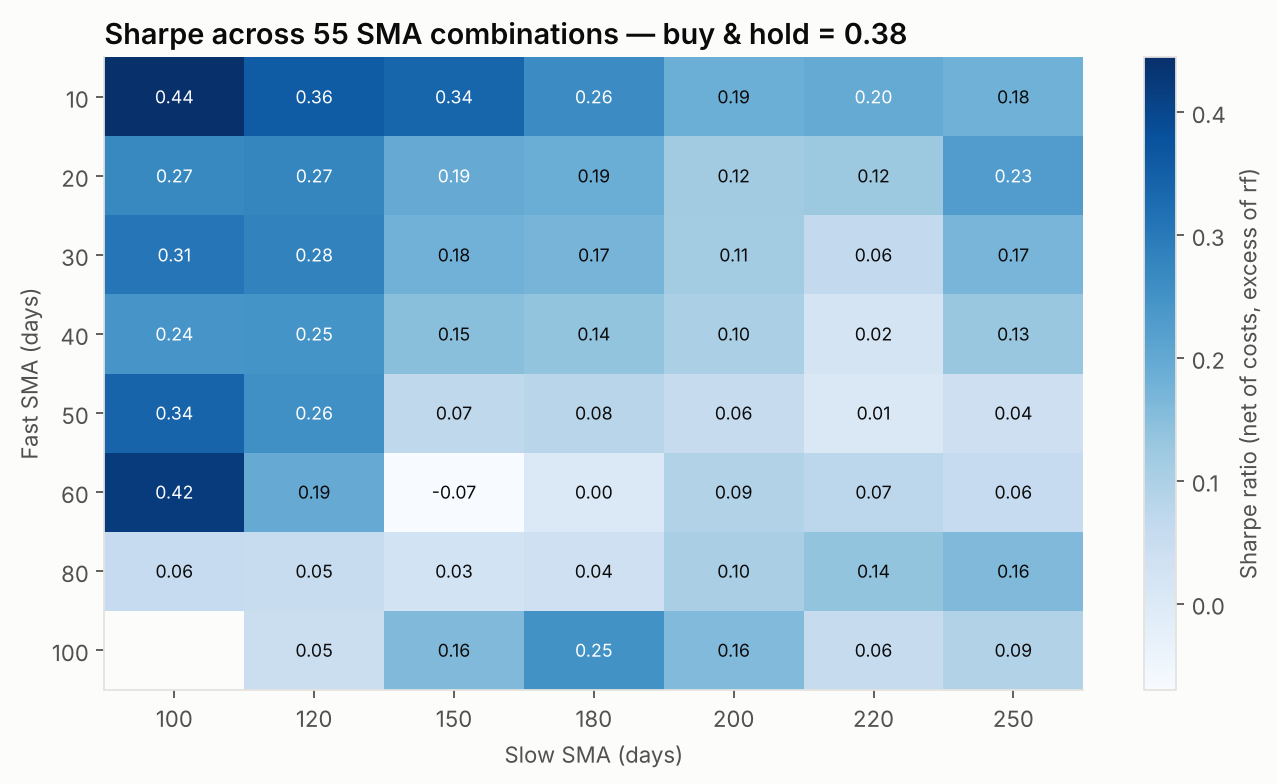

PosixPath('/home/claude/nse-quant-lab/reports/figures/02_param_heatmap.png')

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5))
im = ax.imshow(grid.values.astype(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(slows)), slows); ax.set_yticks(range(len(fasts)), fasts)
ax.set_xlabel("Slow SMA (days)"); ax.set_ylabel("Fast SMA (days)"); ax.grid(False)
for i in range(len(fasts)):
    for j in range(len(slows)):
        v = grid.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > np.nanpercentile(grid.values.astype(float), 70) else "#0b0b0b")
fig.colorbar(im, ax=ax, label="Sharpe ratio (net of costs, excess of rf)")
ax.set_title(f"Sharpe across {len(trial_sr)} SMA combinations — buy & hold = {metrics.sharpe(bh, rf_s):.2f}")
save(fig, "02_param_heatmap")

## 4 · Walk-forward: pick parameters with only past data

Every January, choose the (fast, slow) pair with the best Sharpe over the **previous 5 years**, and
trade it for the next 12 months. This is what you could actually have done in real time.

In [7]:
years = sorted(set(px.index.year))
wf_parts, chosen = [], {}
full_sig = {k: sma_signal(px, *k) for k in trial_rets}
for y in years:
    tr = slice(f"{y-5}-01-01", f"{y-1}-12-31")
    if px.loc[tr].index.size < 252 * 4 or y > px.index[-1].year:
        continue
    scores = {k: metrics.sharpe(run(full_sig[k]).loc[tr], rf.loc[tr]) for k in full_sig}
    k = max(scores, key=scores.get)
    chosen[y] = k
    wf_parts.append(run(full_sig[k]).loc[str(y)])
wf = pd.concat(wf_parts)
bh_wf = ret.loc[wf.index]; rf_wf = rf.loc[wf.index]
wf_tab = metrics.table([metrics.summary(bh_wf, rf_wf, name="Buy & hold (same period)"),
                        metrics.summary(wf, rf_wf, bh_wf, name="Walk-forward SMA")])
print({y: f"{a}/{b}" for y, (a, b) in chosen.items()})
wf_tab[["cagr", "vol", "sharpe", "max_dd", "alpha_ann", "alpha_t"]]

{2017: '100/150', 2018: '100/150', 2019: '80/220', 2020: '80/220', 2021: '10/100', 2022: '10/100', 2023: '10/100', 2024: '10/100', 2025: '10/100', 2026: '60/100'}


,cagr,vol,sharpe,max_dd,alpha_ann,alpha_t
name,,,,,,
Buy & hold (same period),11.5%,16.2%,0.42,-38.4%,nan%,nan
Walk-forward SMA,6.1%,13.2%,0.11,-39.6%,-3.0%,-1.20


## 5 · Robustness: does trend × vol-target help across 12 NIFTY sectors?

In [8]:
sec_rows = []
for label, name in data.SECTORS.items():
    p = data.load(name)
    p = p[p.index >= "2011-01-01"]
    r_ = p.pct_change().fillna(0)
    rf_x = data.risk_free_daily(p.index)
    st = p.index[300]
    ev = np.sqrt((r_**2).ewm(alpha=0.06).mean() * 252)
    strat = run(sma_signal(p, 50, 200) * (TARGET / ev).clip(upper=1), r_, rf_x).loc[st:]
    b = r_.loc[st:]; rr = rf_x.loc[st:]
    sec_rows.append({"sector": label, "bh_sharpe": metrics.sharpe(b, rr), "strat_sharpe": metrics.sharpe(strat, rr),
                     "bh_maxdd": metrics.max_dd(b), "strat_maxdd": metrics.max_dd(strat),
                     "bh_cagr": metrics.cagr(b), "strat_cagr": metrics.cagr(strat)})
sec = pd.DataFrame(sec_rows).set_index("sector").sort_values("bh_sharpe")
sec["sharpe_gain"] = sec.strat_sharpe - sec.bh_sharpe
sec.round(3)

,bh_sharpe,strat_sharpe,bh_maxdd,strat_maxdd,bh_cagr,strat_cagr,sharpe_gain
sector,,,,,,,
Media,-0.110,-0.184,-0.729,-0.151,-0.009,0.034,-0.074
FMCG,0.206,0.075,-0.324,-0.269,0.079,0.060,-0.130
PSU Bank,0.212,0.320,-0.754,-0.229,0.075,0.085,0.109
Realty,0.291,0.159,-0.564,-0.205,0.103,0.069,-0.132
Infra,0.315,0.142,-0.436,-0.209,0.103,0.068,-0.173
Pharma,0.367,0.452,-0.535,-0.122,0.114,0.100,0.084
Bank,0.375,0.069,-0.479,-0.251,0.121,0.059,-0.305
IT,0.388,0.243,-0.440,-0.200,0.122,0.079,-0.144
Energy,0.405,0.137,-0.412,-0.218,0.126,0.067,-0.268


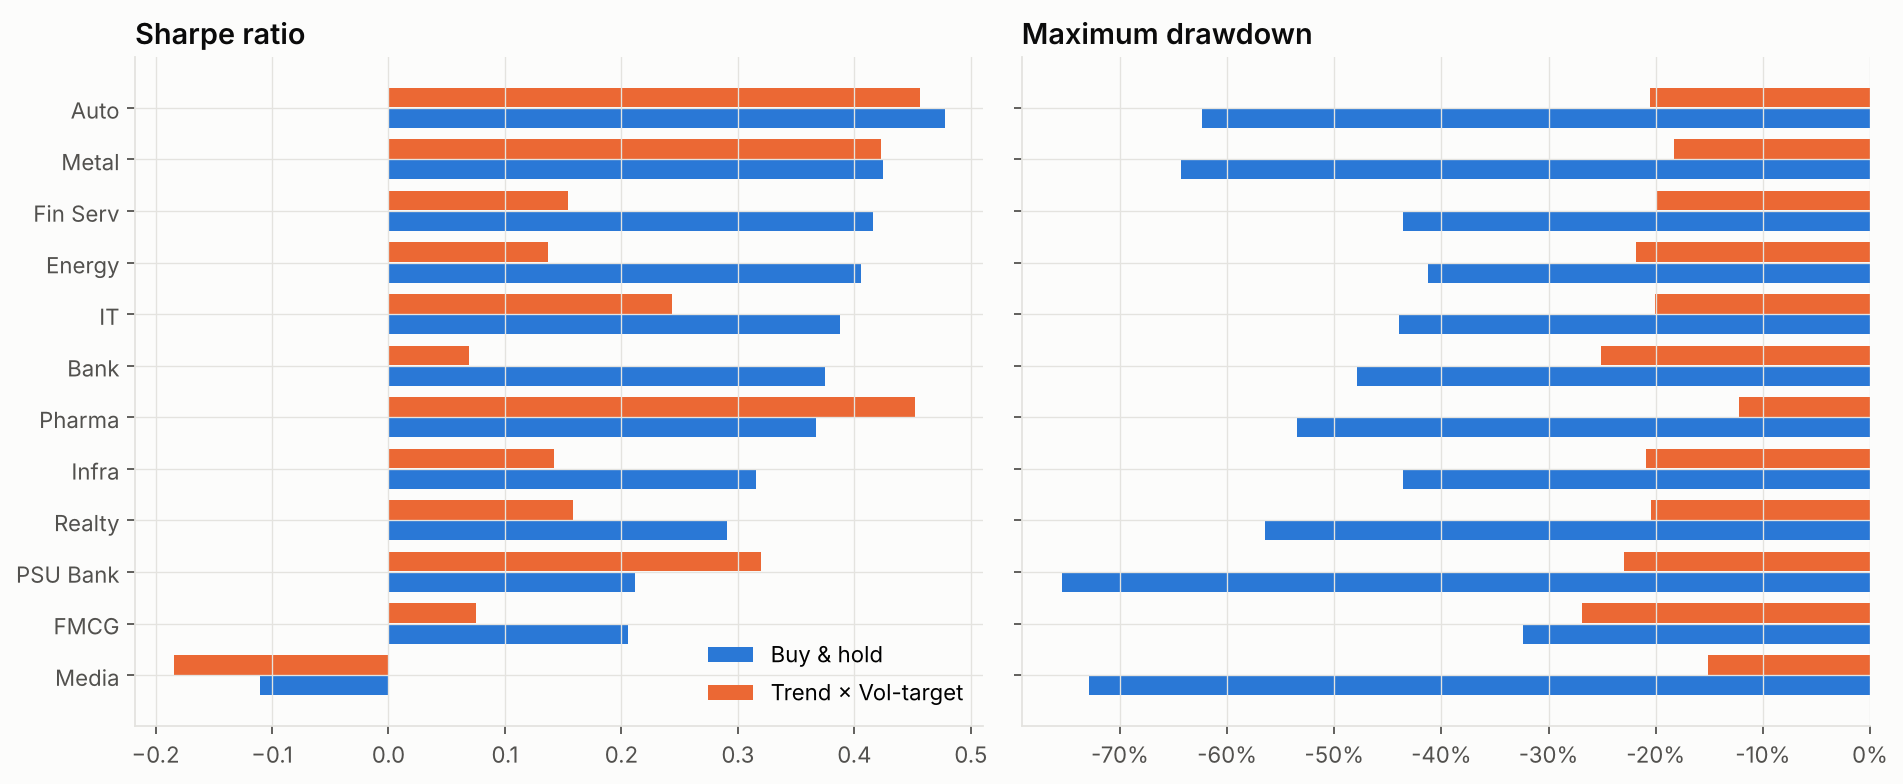

PosixPath('/home/claude/nse-quant-lab/reports/figures/02_sector_robustness.png')

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
y = np.arange(len(sec))
axes[0].barh(y - 0.2, sec.bh_sharpe, 0.38, color=PALETTE[0], label="Buy & hold")
axes[0].barh(y + 0.2, sec.strat_sharpe, 0.38, color=PALETTE[1], label="Trend × Vol-target")
axes[0].set_yticks(y, sec.index); axes[0].set_title("Sharpe ratio"); axes[0].legend(loc="lower right")
axes[1].barh(y - 0.2, sec.bh_maxdd, 0.38, color=PALETTE[0])
axes[1].barh(y + 0.2, sec.strat_maxdd, 0.38, color=PALETTE[1])
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].set_title("Maximum drawdown")
save(fig, "02_sector_robustness")

## Takeaways (from the numbers above, not from folklore)

* **The golden cross failed on NIFTY 50 (2013-2026).** Net of costs it compounded ~5.7% vs ~10.9% for
  buy-and-hold, and its worst drawdown (≈−40%) was *deeper* than the index's: it whipsawed through
  2018-19, sold only after the March-2020 crash (signal flipped the week of 22-Mar-2020) and missed
  the V-shaped rebound. Fast crashes are the Achilles heel of slow trend signals.
* **Volatility targeting is the better risk overlay.** It roughly **halved max drawdown (−38% → −21%)**
  and *raised* the Calmar ratio, at the cost of ~3 pp of CAGR — a clean, explainable trade-off.
* **Parameter mining doesn't rescue it.** Only 2 of 55 SMA pairs beat buy-and-hold's Sharpe; the best
  (10/100) has a Deflated Sharpe Ratio of ~0.75, below the 0.95 bar — indistinguishable from luck
  once you account for 55 tries. The real-time walk-forward version earned ~6.1% vs ~11.5% CAGR.
* **Across 12 sectors**, trend × vol-target cut max drawdown in every sector (often by half or more)
  but improved Sharpe only in the deep-drawdown sectors (PSU Bank, Pharma). In India's 2013-2026 bull
  market, insurance against crashes cost more than it paid.

In [10]:
data.save_results("02_trend", {
    "performance": pd.DataFrame(rows).to_dict(orient="records"),
    "significance": sig, "grid": {f"{f}/{s_}": grid.loc[f, s_] for f in fasts for s_ in slows if f < s_},
    "walk_forward": {"chosen": {str(k): f"{a}/{b}" for k, (a, b) in chosen.items()},
                     "strategy": metrics.summary(wf, rf_wf, bh_wf, name="wf"), "buy_hold": metrics.summary(bh_wf, rf_wf, name="bh")},
    "sectors": sec.reset_index().to_dict(orient="records"),
    "equity_curves": {k: {str(d.date()): x for d, x in ((1 + v).cumprod() * 100).resample("ME").last().round(2).items()} for k, v in series.items()},
})
print("saved")

saved
